# Forty-eight hours before kick-off: International air arrivals at the 2026 World Cup host airports

Replication notebook. It reproduces every number, the table and the three figures of the paper, and the tables and figure of the supplementary material (Section 7), from `data/daily_by_airport.csv` (daily counts built from the U.S. Customs and Border Protection Airport Wait Times data) and `data/wc2026_matches.csv` (the match schedule).

Run all cells. With `DOWNLOAD = True` the daily file is first rebuilt from the CBP site (about 30 minutes); otherwise the copy in the repository is used. Outputs are written to `output/`.

In [1]:
import os, io, re, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy import optimize
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

DOWNLOAD = False                       # True rebuilds data/daily_by_airport.csv from awt.cbp.gov
START, END = '2023-05-03', '2026-10-06'  # sample used in the paper
REPO = 'https://raw.githubusercontent.com/manueleleonelli/worldcup2026-arrivals/main/'
os.makedirs('data', exist_ok=True); os.makedirs('output', exist_ok=True)

HOST_AIRPORTS = {
    'New York/New Jersey': ['JFK', 'EWR'],
    'Los Angeles': ['LAX', 'ONT', 'SNA'],
    'San Francisco Bay Area': ['SFO', 'SJC', 'OAK'],
    'Miami': ['MIA', 'FLL'],
    'Atlanta': ['ATL'], 'Seattle': ['SEA'], 'Dallas': ['DFW'],
    'Houston': ['IAH'], 'Boston': ['BOS'], 'Philadelphia': ['PHL'],
}
MAJOR = ['New York/New Jersey', 'Los Angeles', 'San Francisco Bay Area', 'Miami']
SECONDARY = ['Atlanta', 'Seattle', 'Dallas', 'Houston', 'Boston', 'Philadelphia']
HOSTS = MAJOR + SECONDARY
# US international airports without matches that report on at least 98% of days (Cincinnati, at 91%, is not used)
COMPARISON = ['ORD', 'IAD', 'BWI', 'CLT', 'RDU', 'DTW', 'MSP', 'STL', 'DEN',
              'SLC', 'PHX', 'LAS', 'SAN', 'PDX', 'HNL', 'MCO', 'TPA', 'AUS', 'SAT']
HUBS = ['ORD', 'IAD', 'DEN', 'DTW', 'MSP', 'CLT', 'PHX', 'SLC']   # main connecting hubs of United, Delta and American
AREA = {a: m for m, v in HOST_AIRPORTS.items() for a in v}
AREA.update({a: a for a in COMPARISON})
TOURN_START, TOURN_END = pd.Timestamp('2026-06-11'), pd.Timestamp('2026-07-19')

def load(name, **kw):
    local = os.path.join('data', name)
    return pd.read_csv(local if os.path.exists(local) else REPO + 'data/' + name, **kw)

## 1. Data

### Optional: rebuild the daily file from CBP

The CBP site serves hourly records per airport and terminal through a JSON endpoint, from 3 May 2023 onwards. Airports not in the CBP system return 404 and are skipped.

In [2]:
def fetch(code, start=START, end=END):
    import requests
    frames = []
    for s in pd.date_range(start, end, freq='365D'):
        e = min(s + pd.Timedelta(days=364), pd.Timestamp(end))
        payload = json.dumps({'Id': code, 'FromDate': s.strftime('%Y-%m-%d'), 'ToDate': e.strftime('%Y-%m-%d')})
        for k in range(3):
            try:
                r = requests.post('https://awt.cbp.gov/api/waitTime', data=payload, timeout=180,
                                  headers={'Content-Type': 'application/json', 'Accept': 'application/json'})
                if r.status_code == 404:
                    return pd.DataFrame()
                if r.status_code == 200:
                    js = r.json(); items = js.get('Items', []) if isinstance(js, dict) else js
                    if items: frames.append(pd.json_normalize(items))
                    break
            except Exception:
                pass
            time.sleep(3 * (k + 1))
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def find_col(cols, patterns, exclude=None):
    for p in patterns:
        for c in cols:
            if re.search(p, c, re.I) and not (exclude and re.search(exclude, c, re.I)):
                return c

def to_daily(code, df):
    cols = list(df.columns)
    m = {'date': find_col(cols, [r'flight.?date', r'date']),
         'usa': find_col(cols, [r'^usa.*passeng', r'usa.*count'], r'non|wait|excl'),
         'nonusa': find_col(cols, [r'non.?usa.*passeng', r'non.?us.*count'], r'wait|excl'),
         'total': find_col(cols, [r'(all|total).*passeng', r'total.*count'], r'wait|usa|excl'),
         'flights': find_col(cols, [r'flight.*count'], r'date'),
         'nonusa_max': find_col(cols, [r'non.?usa.*max.*wait', r'non.?us.*max']),
         'usa_max': find_col(cols, [r'^usa.*max.*wait'], r'non'),
         'all_max': find_col(cols, [r'all.*max.*wait', r'max.*wait'], r'usa'),
         'nonusa_avg': find_col(cols, [r'non.?usa.*(avg|average).*wait', r'non.?us.*(avg|average)']),
         'all_avg': find_col(cols, [r'all.*(avg|average).*wait', r'(avg|average).*wait'], r'usa')}
    t = pd.DataFrame({'airport': code, 'date': pd.to_datetime(df[m['date']], errors='coerce').dt.normalize()})
    for k in m:
        if k != 'date':
            t[k] = pd.to_numeric(df[m[k]], errors='coerce') if m[k] else np.nan
    t['_wn'] = t.nonusa_avg * t.nonusa; t['_wa'] = t.all_avg * t.total
    d = t.dropna(subset=['date']).groupby(['airport', 'date']).agg(
        usa=('usa', 'sum'), nonusa=('nonusa', 'sum'), total=('total', 'sum'), flights=('flights', 'sum'),
        nonusa_max_wait=('nonusa_max', 'max'), usa_max_wait=('usa_max', 'max'), all_max_wait=('all_max', 'max'),
        _wn=('_wn', 'sum'), _wa=('_wa', 'sum')).reset_index()
    d['nonusa_avg_wait'] = d._wn / d.nonusa.replace(0, np.nan); d['all_avg_wait'] = d._wa / d.total.replace(0, np.nan)
    return d.drop(columns=['_wn', '_wa'])

if DOWNLOAD:
    parts = []
    for code_ in sorted(AREA):
        raw = fetch(code_)
        print(code_, len(raw), 'hourly rows')
        if len(raw): parts.append(to_daily(code_, raw))
    pd.concat(parts).sort_values(['airport', 'date']).to_csv('data/daily_by_airport.csv', index=False)

### Daily series by area and match schedule

In [3]:
airport = load('daily_by_airport.csv', parse_dates=['date'])
airport = airport[(airport.date >= START) & (airport.date <= END) & airport.airport.isin(AREA)]
airport['area'] = airport.airport.map(AREA)
daily = airport.groupby(['area', 'date']).agg(
    nonusa=('nonusa', 'sum'), total=('total', 'sum'), nonusa_max_wait=('nonusa_max_wait', 'max')).reset_index()
full = pd.MultiIndex.from_product([daily.area.unique(), pd.date_range(START, END)], names=['area', 'date'])
daily = daily.set_index(['area', 'date']).reindex(full).reset_index()

matches = load('wc2026_matches.csv', parse_dates=['date'])
us = matches[matches.metro.isin(HOSTS)]
match_dates = {m: sorted(g.date) for m, g in us.groupby('metro')}
window_days = {m: {x for d in ds for x in pd.date_range(d - pd.Timedelta(days=2), d + pd.Timedelta(days=1))}
               for m, ds in match_dates.items()}

print(airport.airport.nunique(), 'airports,', daily.area.nunique(), 'areas,', daily.date.nunique(), 'days')
print(len(us), 'of', (matches.country == 'US').sum(), 'US matches covered')
avg = daily.groupby('area').nonusa.mean().round(0)
print('Average daily non-US arrivals by host area:'); print(avg[HOSTS].sort_values(ascending=False).to_string())

35 airports, 29 areas, 1253 days
72 of 78 US matches covered
Average daily non-US arrivals by host area:
area
New York/New Jersey       27926.0
Miami                     19778.0
Los Angeles               13848.0
San Francisco Bay Area     8994.0
Houston                    6386.0
Dallas                     5509.0
Atlanta                    5223.0
Boston                     3638.0
Seattle                    3083.0
Philadelphia                824.0


### Study airports (Figure 1)

Airport coordinates come from OurAirports and state boundaries from Natural Earth, both in the public domain (`scripts/make_map_data.py` builds the two files). Hubs are the comparison airports left out in the connecting-traffic checks of Section 7.5.

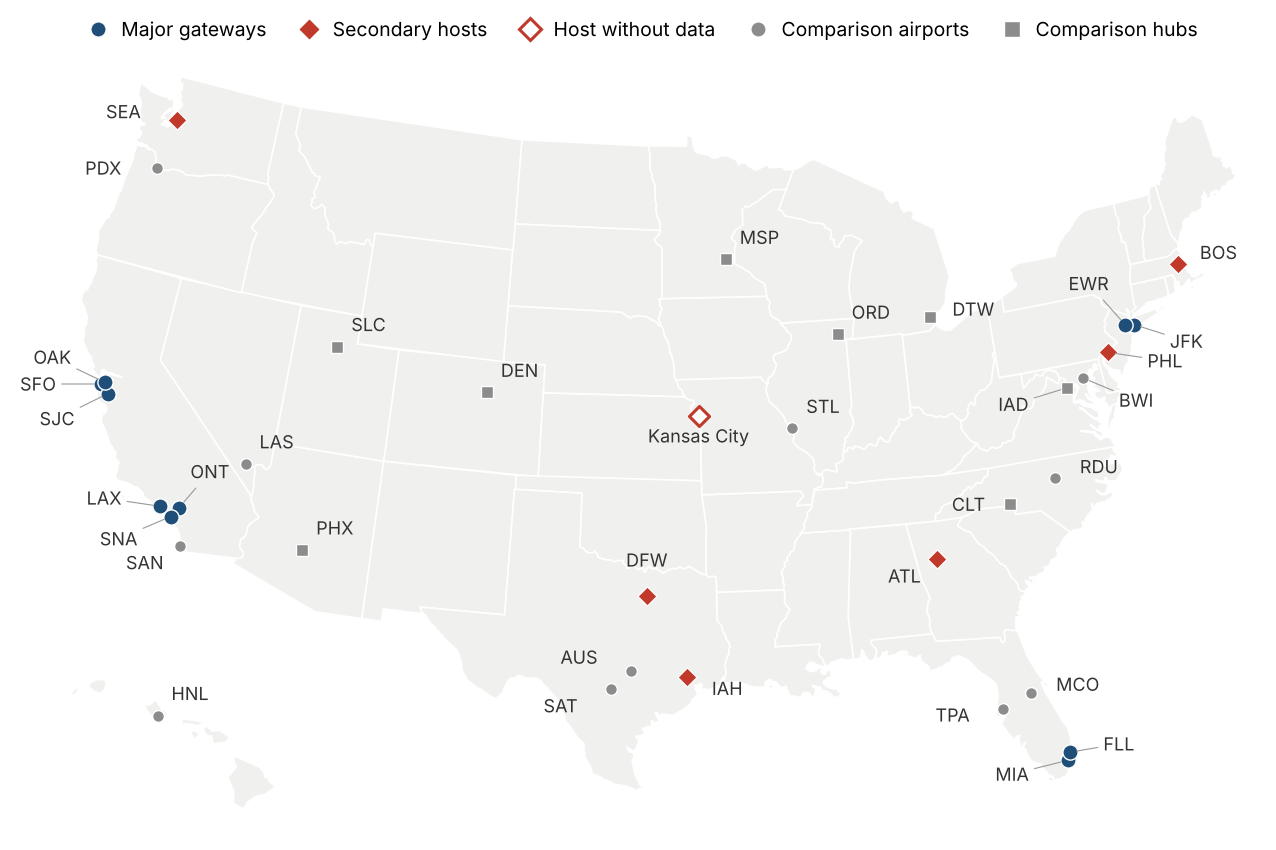

In [4]:
import geopandas as gpd
from matplotlib.lines import Line2D

def load_path(name):
    local = os.path.join('data', name)
    return local if os.path.exists(local) else REPO + 'data/' + name

states = gpd.read_file(load_path('us_states.geojson'))
ap = load('airports.csv')
ap = ap[ap.iata.isin(list(AREA) + ['MCI'])]
MAJOR_AP = [a for m in MAJOR for a in HOST_AIRPORTS[m]]
SECOND_AP = [a for m in SECONDARY for a in HOST_AIRPORTS[m]]
STYLE = {'major': dict(marker='o', s=30, color='#1f4e79', edgecolor='white', linewidth=0.5, zorder=4),
         'secondary': dict(marker='D', s=24, color='#c0392b', edgecolor='white', linewidth=0.5, zorder=4),
         'comparison': dict(marker='o', s=18, color='#8c8c8c', edgecolor='white', linewidth=0.5, zorder=3),
         'hub': dict(marker='s', s=18, color='#8c8c8c', edgecolor='white', linewidth=0.5, zorder=3),
         'nodata': dict(marker='D', s=26, facecolor='white', edgecolor='#c0392b', linewidth=1.1, zorder=4)}
ap['group'] = np.select([ap.iata.isin(MAJOR_AP), ap.iata.isin(SECOND_AP), ap.iata.isin(HUBS), ap.iata == 'MCI'],
                        ['major', 'secondary', 'hub', 'nodata'], 'comparison')
ap['label'] = ap.iata.where(ap.iata != 'MCI', 'Kansas City')
# label offsets in points (dx, dy); a leader line is drawn when the label sits away from a crowded point
OFFSET = {'SFO': (-16, 0), 'OAK': (-12, 9), 'SJC': (-12, -9), 'LAX': (-14, 3), 'ONT': (4, 9), 'SNA': (-12, -8),
          'SAN': (-6, -10), 'JFK': (13, -6), 'EWR': (-6, 11), 'PHL': (14, -3), 'BWI': (13, -8), 'IAD': (-14, -6),
          'BOS': (8, 4), 'MIA': (-14, -5), 'FLL': (12, 3), 'MCO': (9, 3), 'TPA': (-12, -2), 'AUS': (-12, 5),
          'SAT': (-12, -6), 'IAH': (9, -4), 'DFW': (0, 9), 'RDU': (9, 4), 'CLT': (-9, 0), 'ATL': (-6, -10),
          'PDX': (-13, 0), 'SEA': (-13, 3), 'DTW': (8, 3), 'Kansas City': (0, -11)}
LEADER = {'SFO', 'OAK', 'SJC', 'LAX', 'ONT', 'SNA', 'JFK', 'EWR', 'PHL', 'BWI', 'IAD', 'MIA', 'FLL'}

def draw(ax, crs, rows, bounds=None):
    st = states.to_crs(crs)
    st.plot(ax=ax, facecolor='#f0f0ee', edgecolor='white', linewidth=0.6)
    pts = gpd.GeoDataFrame(rows, geometry=gpd.points_from_xy(rows.lon, rows.lat), crs=4326).to_crs(crs)
    for g, d in pts.groupby('group'):
        ax.scatter(d.geometry.x, d.geometry.y, **STYLE[g])
    for _, r in pts.iterrows():
        dx, dy = OFFSET.get(r.label, (5, 4))
        ax.annotate(r.label, (r.geometry.x, r.geometry.y), xytext=(dx, dy), textcoords='offset points', fontsize=6.5,
                    ha='left' if dx > 0 else 'right' if dx < 0 else 'center', va='center' if dy == 0 or abs(dx) > 6 else 'bottom',
                    color='#333333', zorder=5,
                    arrowprops=dict(arrowstyle='-', color='#999999', lw=0.4, shrinkA=0, shrinkB=2.5) if r.label in LEADER else None)
    if bounds is not None:
        ax.set_xlim(bounds[0], bounds[2]); ax.set_ylim(bounds[1], bounds[3])
    ax.set_axis_off()

plt.rcParams.update({'font.size': 8})
fig = plt.figure(figsize=(6.5, 4.1))
ax = fig.add_axes([0, 0, 1, 0.93])
conus = states[~states.postal.isin(['AK', 'HI'])]
x0, y0, x1, y1 = conus.to_crs(5070).total_bounds
draw(ax, 5070, ap[ap.iata != 'HNL'], (x0 - 220e3, y0 - 120e3, x1 + 80e3, y1 + 30e3))
ax_hi = fig.add_axes([0.04, 0.02, 0.2, 0.17])
hi = states[states.postal == 'HI'].clip((-160.6, 18.7, -154.5, 22.5)).to_crs('ESRI:102007').total_bounds
draw(ax_hi, 'ESRI:102007', ap[ap.iata == 'HNL'], (hi[0] - 15e3, hi[1] - 15e3, hi[2] + 15e3, hi[3] + 15e3))
handles = []
for g, lab in (('major', 'Major gateways'), ('secondary', 'Secondary hosts'), ('nodata', 'Host without data'),
               ('comparison', 'Comparison airports'), ('hub', 'Comparison hubs')):
    k = STYLE[g]
    handles.append(Line2D([], [], ls='', marker=k['marker'], markersize=5.5, label=lab,
                          markerfacecolor=k.get('facecolor', k.get('color')), markeredgecolor=k.get('edgecolor', k.get('color')),
                          markeredgewidth=k.get('linewidth', 0.5)))
fig.legend(handles=handles, frameon=False, loc='upper center', ncol=5, fontsize=7, handletextpad=0.2, columnspacing=1.2)
fig.savefig('output/figure1_airports.pdf'); fig.savefig('output/figure1_airports.png', dpi=300); plt.show()

## 2. Year-on-year comparison and peak rank (Table 1, columns 2 and 3)

In [5]:
def window_sum(areas, year):
    d0, d1 = TOURN_START.replace(year=year), TOURN_END.replace(year=year)
    return daily[daily.area.isin(areas) & (daily.date >= d0) & (daily.date <= d1)].nonusa.sum()

rows = []
for m in HOSTS:
    d = daily[daily.area == m].dropna(subset=['nonusa'])
    hist, tw = d[d.date < TOURN_START], d[(d.date >= TOURN_START) & (d.date <= TOURN_END)]
    pk = tw.loc[tw.nonusa.idxmax()]
    rows.append({'area': m, 'matches': len(match_dates[m]),
                 'change_pct': 100 * (window_sum([m], 2026) / window_sum([m], 2025) - 1),
                 'peak_rank': int((hist.nonusa >= pk.nonusa).sum()) + 1, 'peak_date': pk.date.date(),
                 'peak_vs_previous_max_pct': 100 * (pk.nonusa / hist.nonusa.max() - 1)})
desc = pd.DataFrame(rows).set_index('area')
groups = {'Major gateways': MAJOR, 'Secondary hosts': SECONDARY, 'All hosts': HOSTS, 'Comparison airports': COMPARISON}
group_change = {g: 100 * (window_sum(a, 2026) / window_sum(a, 2025) - 1) for g, a in groups.items()}
print('Pre-tournament days:', daily[daily.date < TOURN_START].date.nunique())
print('Host total in the tournament window: %.0f' % window_sum(HOSTS, 2026))
display(desc.round(1)); print({g: round(v, 1) for g, v in group_change.items()})

Pre-tournament days: 1135
Host total in the tournament window: 3788497


,matches,change_pct,peak_rank,peak_date,peak_vs_previous_max_pct
area,,,,,
New York/New Jersey,8,-6.8,160,2026-06-12,-25.4
Los Angeles,8,2.1,74,2026-07-17,-22.6
San Francisco Bay Area,6,-1.8,139,2026-07-18,-20.2
Miami,7,-1.8,88,2026-07-10,-27.8
Atlanta,8,0.7,53,2026-07-14,-22.5
Seattle,6,-2.3,25,2026-07-12,-8.0
Dallas,9,23.8,4,2026-07-13,-11.5
Houston,7,11.5,23,2026-06-22,-17.5
Boston,7,11.8,1,2026-06-11,15.5


{'Major gateways': np.float64(-3.1), 'Secondary hosts': np.float64(9.9), 'All hosts': np.float64(0.3), 'Comparison airports': np.float64(-0.5)}


## 3. Synthetic control (Table 1, columns 4 to 6, and Figure 2)

Weekly log non-US arrivals. The synthetic control of a host is a weighted average of the nineteen comparison airports (non-negative weights summing to one) plus a constant, fitted from the first full week of May 2023 (the data start on 3 May 2023) to the week before the tournament. The gap over the six tournament weeks gives the uplift and the excess arrivals. Each comparison airport is then treated in turn as a placebo, with a synthetic control built from the other eighteen, and the host's post/pre ratio of root mean squared prediction error is ranked among the twenty units (the host and the nineteen placebos).

In [6]:
daily['week'] = daily.date - pd.to_timedelta(daily.date.dt.weekday, unit='D')
wk = daily.groupby(['area', 'week']).agg(nonusa=('nonusa', 'sum'), n=('nonusa', 'count')).reset_index()
wk = wk[wk.n == 7]
W = np.log(wk.pivot(index='week', columns='area', values='nonusa').loc['2023-01-02':].replace(0, np.nan))
PRE_END = pd.Timestamp('2026-06-01')
TW = pd.date_range('2026-06-08', '2026-07-13', freq='7D')
donors = [a for a in COMPARISON if W[a].loc[:PRE_END].notna().mean() > 0.9]
print(len(donors), 'comparison airports used; excluded:', [a for a in COMPARISON if a not in donors])

def synth(y, D):
    ybar, Dbar = y.mean(), D.mean(axis=0); Y, X = y - ybar, D - Dbar; J = X.shape[1]
    res = optimize.minimize(lambda w: np.sum((Y - X @ w) ** 2), np.ones(J) / J, bounds=[(0, 1)] * J,
                            constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP',
                            options={'maxiter': 2000, 'ftol': 1e-12})
    w = np.clip(res.x, 0, None); w[w < 1e-4] = 0; w /= w.sum()
    return w, ybar - Dbar @ w

def run_sc(unit, pool):
    M = W[[unit] + pool].dropna(); pre = M[M.index <= PRE_END]; post = M.index.isin(TW)
    w, a = synth(pre[unit].values, pre[pool].values)
    syn = pd.Series(M[pool].values @ w + a, index=M.index); gap = M[unit] - syn
    return dict(w=pd.Series(w, index=pool), syn=syn, obs=M[unit],
                ratio=np.sqrt((gap[post] ** 2).mean()) / np.sqrt((gap[M.index <= PRE_END] ** 2).mean()),
                uplift=100 * (np.exp(gap[post].mean()) - 1),
                excess=(np.exp(M[unit][post]) - np.exp(syn[post])).sum())

placebo = [run_sc(a, [b for b in donors if b != a])['ratio'] for a in donors]
sc, rows = {}, []
for m in HOSTS:
    r = run_sc(m, donors); sc[m] = r
    rows.append({'area': m, 'uplift_pct': r['uplift'], 'excess_thousands': r['excess'] / 1000,
                 'rank_of_20': int(np.sum(np.array(placebo) >= r['ratio'])) + 1})
sctab = pd.DataFrame(rows).set_index('area')
weights = pd.DataFrame({m: sc[m]['w'] for m in HOSTS}).T.round(3)
weights.to_csv('output/synthetic_control_weights.csv')
display(sctab.round(1))
print('Excess (thousands): major %.0f, secondary %.0f, all %.0f' % (
    sctab.loc[MAJOR].excess_thousands.sum(), sctab.loc[SECONDARY].excess_thousands.sum(), sctab.excess_thousands.sum()))
print('\nLargest weights:')
for m in HOSTS:
    print('  %-24s' % m, ', '.join(f'{k} {v:.2f}' for k, v in weights.loc[m].sort_values(ascending=False).head(3).items()))

19 comparison airports used; excluded: []


,uplift_pct,excess_thousands,rank_of_20
area,,,
New York/New Jersey,-4.8,-58.6,4
Los Angeles,1.4,7.5,11
San Francisco Bay Area,-4.4,-17.5,5
Miami,-5.5,-45.3,6
Atlanta,-3.2,-7.5,8
Seattle,7.2,10.4,8
Dallas,15.4,34.8,1
Houston,4.8,12.2,1
Boston,18.9,31.3,1


Excess (thousands): major -114, secondary 89, all -25

Largest weights:
  New York/New Jersey      IAD 0.48, HNL 0.16, SAT 0.11
  Los Angeles              HNL 0.25, IAD 0.23, LAS 0.14
  San Francisco Bay Area   DTW 0.26, IAD 0.15, ORD 0.14
  Miami                    PHX 0.38, HNL 0.29, SAT 0.14
  Atlanta                  IAD 0.31, PHX 0.29, DTW 0.12
  Seattle                  PDX 0.20, MSP 0.19, DTW 0.19
  Dallas                   PHX 0.31, IAD 0.26, HNL 0.22
  Houston                  IAD 0.33, PHX 0.23, HNL 0.21
  Boston                   ORD 0.46, MSP 0.22, IAD 0.14
  Philadelphia             MSP 0.55, CLT 0.30, BWI 0.05


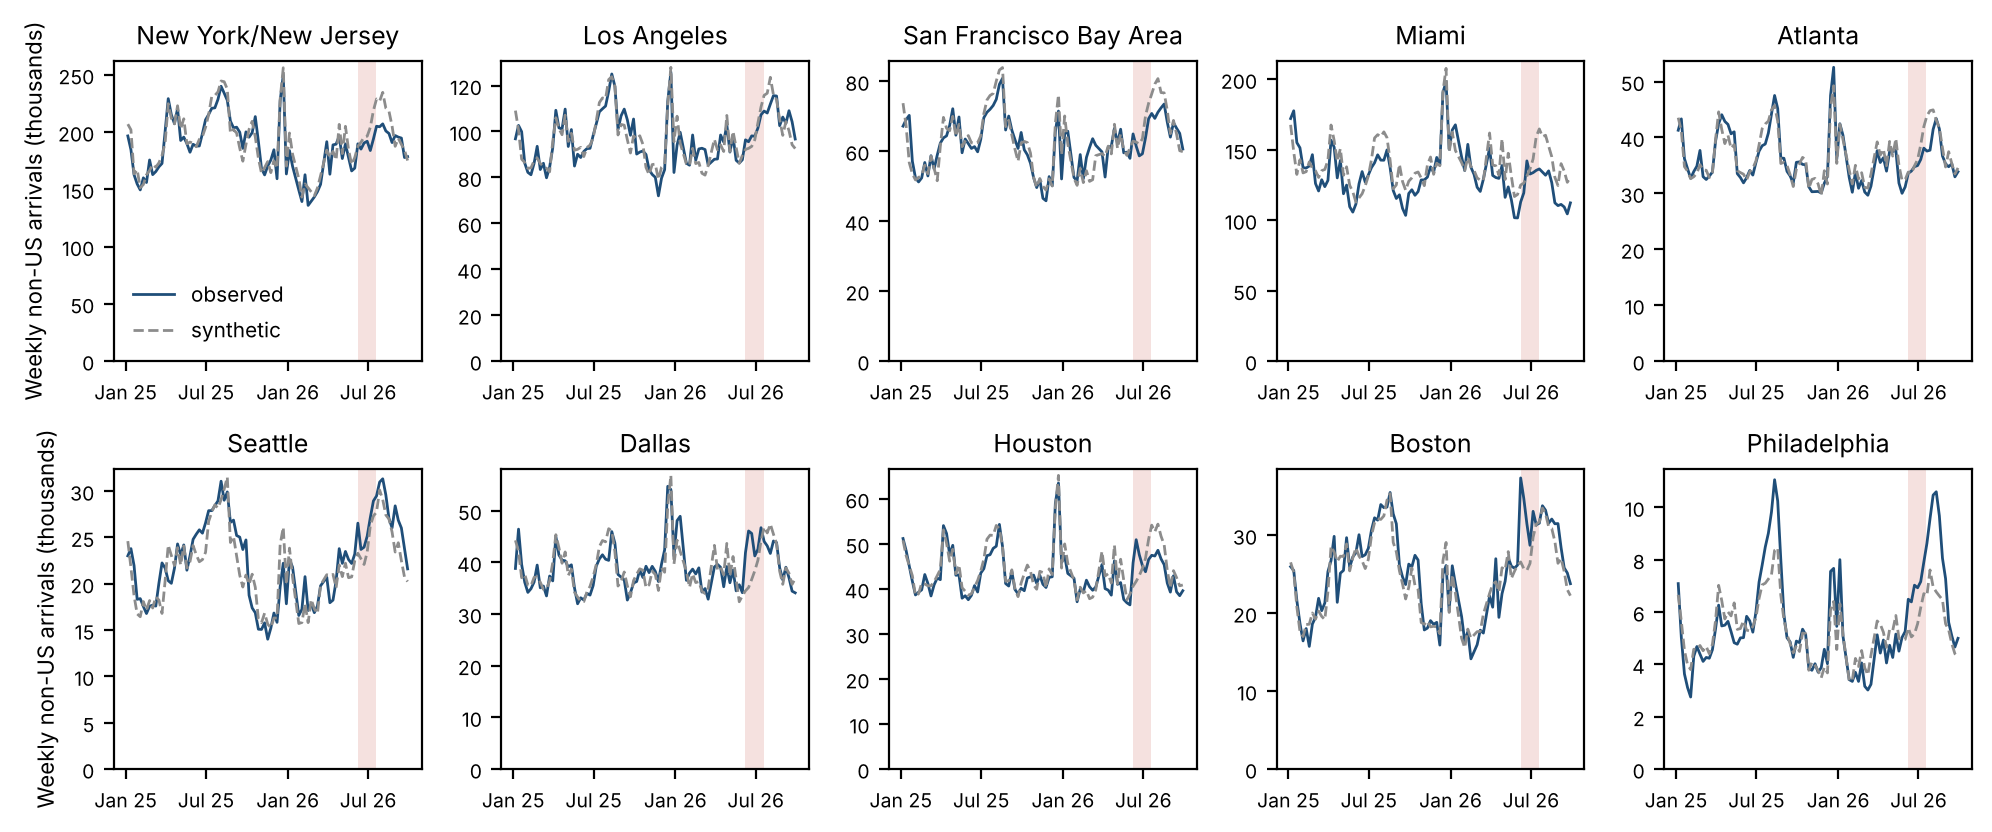

In [7]:
plt.rcParams.update({'font.size': 8, 'axes.titlesize': 9, 'legend.fontsize': 7.5})
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for ax, m in zip(axes.flat, HOSTS):
    r = sc[m]; idx = r['obs'].loc['2025-01-01':].index
    ax.plot(idx, np.exp(r['obs'].loc[idx]) / 1000, color='#1f4e79', lw=1.0, label='observed')
    ax.plot(idx, np.exp(r['syn'].loc[idx]) / 1000, color='#8c8c8c', lw=1.0, ls='--', label='synthetic')
    ax.axvspan(TW[0], TW[-1] + pd.Timedelta(days=6), color='#c0392b', alpha=0.15, lw=0)
    ax.set_title(m); ax.set_ylim(0, None); ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
axes[0, 0].legend(frameon=False, loc='lower left')
for ax in axes[:, 0]: ax.set_ylabel('Weekly non-US arrivals (thousands)')
fig.tight_layout(); fig.savefig('output/figure2_synthetic.pdf'); fig.savefig('output/figure2_synthetic.png', dpi=200); plt.show()

### Pooled weekly regression and week-by-week effects

In [8]:
lw = W.loc[:TW[-1] + pd.Timedelta(weeks=8)].stack().rename('ly').reset_index(); lw.columns = ['week', 'area', 'ly']; lw = lw.dropna()
lw['host'] = lw.area.isin(HOSTS).astype(int); lw['tourn'] = lw.week.isin(TW).astype(int); lw['post'] = (lw.week > TW[-1]).astype(int)
fw = smf.ols('ly ~ C(area) + C(week) + host:tourn + host:post', data=lw).fit(cov_type='cluster', cov_kwds={'groups': lw.area})
print('Pooled tournament-week effect: %.1f%% (SE %.1f percentage points)' % (100 * (np.exp(fw.params['host:tourn']) - 1), 100 * fw.bse['host:tourn']))
for k, w in enumerate(TW, 1): lw[f'h{k}'] = ((lw.week == w) & (lw.host == 1)).astype(int)
fw2 = smf.ols('ly ~ C(area) + C(week) + ' + ' + '.join(f'h{k}' for k in range(1, 7)) + ' + host:post', data=lw).fit(
    cov_type='cluster', cov_kwds={'groups': lw.area})
es = pd.DataFrame({'week_start': TW.date, 'effect_pct': [100 * (np.exp(fw2.params[f'h{k}']) - 1) for k in range(1, 7)],
                   'se_pp': [100 * fw2.bse[f'h{k}'] for k in range(1, 7)]})
es.to_csv('output/weekly_effects.csv', index=False); display(es.round(1))

Pooled tournament-week effect: -4.6% (SE 5.8 percentage points)


,week_start,effect_pct,se_pp
0,2026-06-08,1.3,7.3
1,2026-06-15,1.3,6.3
2,2026-06-22,-0.4,5.6
3,2026-06-29,-6.6,5.8
4,2026-07-06,-10.3,6.2
5,2026-07-13,-12.0,5.9


## 4. Daily match-window regression (Table 1, columns 7 and 8, and Figure 3)

$\log y_{it} = \alpha_i + \delta_t + \sum_j \beta_j W_{ijt} + \varepsilon_{it}$ for 1 May to 31 August, with $W_{ijt}=1$ on the match-window days of host $j$ (two days before a match to the day after). The 2025 placebo moves every match date back 364 days, onto the same weekday.

In [9]:
def design(year):
    shift = pd.Timedelta(days=364 * (2026 - year))
    d = daily[(daily.date >= f'{year}-05-01') & (daily.date <= f'{year}-08-31') & (daily.nonusa > 0)].copy()
    d['ly'] = np.log(d.nonusa); d['host'] = d.area.isin(HOSTS).astype(int)
    d['window'] = [int(m in window_days and (t + shift) in window_days[m]) for m, t in zip(d.area, d.date)]
    for i, m in enumerate(HOSTS): d[f'w{i}'] = ((d.area == m) & (d.window == 1)).astype(int)
    def rel(m, t):
        if m not in match_dates: return np.nan
        k = min([(t + shift - x).days for x in match_dates[m]], key=abs)
        return k if -5 <= k <= 4 else np.nan
    d['rel'] = [rel(m, t) for m, t in zip(d.area, d.date)]
    for k in range(-5, 5): d[f'r{k+5}'] = ((d.rel == k) & (d.host == 1)).astype(int)
    return d

res = {}
for year in (2026, 2025):
    d = design(year)
    per = smf.ols('ly ~ C(area) + C(date) + ' + ' + '.join(f'w{i}' for i in range(len(HOSTS))), data=d).fit(cov_type='HC1')
    pooled = smf.ols('ly ~ C(area) + C(date) + window', data=d).fit(cov_type='cluster', cov_kwds={'groups': d.area})
    prof = smf.ols('ly ~ C(area) + C(date) + ' + ' + '.join(f'r{k+5}' for k in range(-5, 5)), data=d).fit(
        cov_type='cluster', cov_kwds={'groups': d.area})
    res[year] = dict(per_fit=per, pooled_fit=pooled,
        per=pd.DataFrame({'effect_pct': [100 * (np.exp(per.params[f'w{i}']) - 1) for i in range(len(HOSTS))],
                          't': [per.params[f'w{i}'] / per.bse[f'w{i}'] for i in range(len(HOSTS))]}, index=HOSTS),
        pooled=(100 * (np.exp(pooled.params['window']) - 1), 100 * pooled.bse['window']),
        prof=pd.DataFrame({'day': range(-5, 5), 'b': [prof.params[f'r{k+5}'] for k in range(-5, 5)],
                           's': [prof.bse[f'r{k+5}'] for k in range(-5, 5)]}))
    print(year, 'pooled match-window effect: %.1f%% (SE %.1f percentage points)' % res[year]['pooled'])
mw = res[2026]['per'].join(res[2025]['per'], lsuffix='_2026', rsuffix='_2025'); display(mw.round(1))
profile = pd.DataFrame({'day': range(-5, 5), 'effect_2026_pct': 100 * (np.exp(res[2026]['prof'].b) - 1),
                        'effect_2025_pct': 100 * (np.exp(res[2025]['prof'].b) - 1)})
profile.to_csv('output/match_day_profile.csv', index=False); display(profile.round(1))

2026 pooled match-window effect: 8.1% (SE 2.9 percentage points)


2025 pooled match-window effect: 2.5% (SE 2.1 percentage points)


,effect_pct_2026,t_2026,effect_pct_2025,t_2025
New York/New Jersey,4.3,2.0,3.8,1.7
Los Angeles,2.8,1.4,2.1,1.1
San Francisco Bay Area,0.2,0.1,1.8,0.7
Miami,13.9,4.2,9.6,3.7
Atlanta,1.1,0.5,-1.4,-0.6
Seattle,0.3,0.1,12.3,4.4
Dallas,16.2,5.2,-0.2,-0.1
Houston,20.8,6.0,2.8,1.2
Boston,21.7,5.4,5.3,2.0
Philadelphia,0.9,0.2,-10.4,-2.0


,day,effect_2026_pct,effect_2025_pct
0,-5,-2.2,8.2
1,-4,4.6,5.5
2,-3,5.6,-0.9
3,-2,12.8,3.7
4,-1,16.3,3.1
5,0,2.4,2.0
6,1,4.6,1.7
7,2,-1.8,-0.7
8,3,2.5,1.1
9,4,-4.7,-2.9


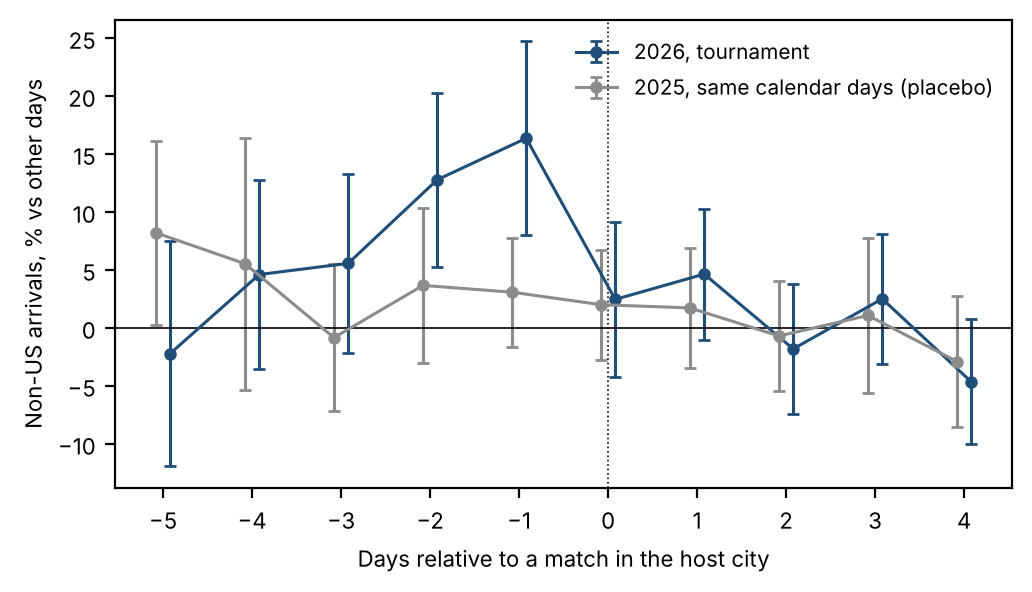

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 3.0))
for yr, c, lab, off in ((2026, '#1f4e79', '2026, tournament', 0.08), (2025, '#8c8c8c', '2025, same calendar days (placebo)', -0.08)):
    p = res[yr]['prof']
    ax.errorbar(p.day + off, 100 * (np.exp(p.b) - 1), yerr=100 * 1.96 * p.s, fmt='o-', color=c, ms=3.5, lw=1.1, capsize=2, label=lab)
ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6, ls=':')
ax.set_xlabel('Days relative to a match in the host city'); ax.set_ylabel('Non-US arrivals, % vs other days')
ax.set_xticks(range(-5, 5)); ax.legend(frameon=False, loc='upper right')
fig.tight_layout(); fig.savefig('output/figure3_profile.pdf'); fig.savefig('output/figure3_profile.png', dpi=200); plt.show()

## 5. Waiting times (Table 1, column 9)

Difference, in minutes, between the 90th percentile of the daily maximum non-US-citizen wait on match-window days and on other days of June and July 2026.

In [11]:
jj = daily[(daily.date.dt.year == 2026) & daily.date.dt.month.isin([6, 7]) & daily.area.isin(HOSTS)].dropna(subset=['nonusa_max_wait'])
jj['window'] = [t in window_days.get(m, set()) for m, t in zip(jj.area, jj.date)]
waits = jj.groupby(['area', 'window']).nonusa_max_wait.quantile(0.9).unstack()
waits['difference_min'] = waits[True] - waits[False]
waits['median_daily_max'] = jj.groupby('area').nonusa_max_wait.median()
display(waits.loc[HOSTS].round(0))

window,False,True,difference_min,median_daily_max
area,,,,
New York/New Jersey,186.0,195.0,8.0,147.0
Los Angeles,120.0,119.0,-0.0,93.0
San Francisco Bay Area,104.0,121.0,17.0,90.0
Miami,140.0,126.0,-13.0,103.0
Atlanta,91.0,85.0,-6.0,61.0
Seattle,152.0,141.0,-11.0,122.0
Dallas,118.0,125.0,8.0,78.0
Houston,133.0,128.0,-6.0,97.0
Boston,97.0,108.0,11.0,77.0


## 6. Table 1

In [12]:
t1 = desc[['matches', 'change_pct', 'peak_rank']].join(sctab).join(mw[['effect_pct_2026', 'effect_pct_2025']]).join(waits[['difference_min']])
t1 = t1.loc[HOSTS]
t1.to_csv('output/table1.csv')

def f(x, d=1):
    if pd.isna(x): return ''
    x = round(x, d) + 0.0
    if x == 0: x = 0.0
    s = f'{abs(x):.{d}f}' if x == 0 else f'{x:.{d}f}'
    return f'${s}$' if x < 0 else s

lines = []
for label, areas in (('Major gateways', MAJOR), ('Secondary hosts', SECONDARY)):
    lines.append(r'\multicolumn{10}{l}{\textit{%s}} \\' % label)
    for m in areas:
        r = t1.loc[m]
        lines.append(f"{m} & {int(r.matches)} & {f(r.change_pct)} & {int(r.peak_rank)} & {f(r.uplift_pct)} & {f(r.excess_thousands)} & "
                     f"{int(r.rank_of_20)} & {f(r.effect_pct_2026)} & {f(r.effect_pct_2025)} & {f(r.difference_min, 0)} \\\\")
    lines.append(f"\\quad Total & & {f(group_change[label])} & & & {f(t1.loc[areas].excess_thousands.sum())} & & & & \\\\")
lines.append(r'\midrule')
lines.append(f"All hosts & & {f(group_change['All hosts'])} & & & {f(t1.excess_thousands.sum())} & & "
             f"{f(res[2026]['pooled'][0])} & {f(res[2025]['pooled'][0])} & \\\\")
lines.append(f"Comparison airports & & {f(group_change['Comparison airports'])} & & & & & & & \\\\")
open('output/table1_rows.tex', 'w').write('\n'.join(lines) + '\n')
print('\n'.join(lines))

\multicolumn{10}{l}{\textit{Major gateways}} \\
New York/New Jersey & 8 & $-6.8$ & 160 & $-4.8$ & $-58.6$ & 4 & 4.3 & 3.8 & 8 \\
Los Angeles & 8 & 2.1 & 74 & 1.4 & 7.5 & 11 & 2.8 & 2.1 & 0 \\
San Francisco Bay Area & 6 & $-1.8$ & 139 & $-4.4$ & $-17.5$ & 5 & 0.2 & 1.8 & 17 \\
Miami & 7 & $-1.8$ & 88 & $-5.5$ & $-45.3$ & 6 & 13.9 & 9.6 & $-13$ \\
\quad Total & & $-3.1$ & & & $-113.8$ & & & & \\
\multicolumn{10}{l}{\textit{Secondary hosts}} \\
Atlanta & 8 & 0.7 & 53 & $-3.2$ & $-7.5$ & 8 & 1.1 & $-1.4$ & $-6$ \\
Seattle & 6 & $-2.3$ & 25 & 7.2 & 10.4 & 8 & 0.3 & 12.3 & $-11$ \\
Dallas & 9 & 23.8 & 4 & 15.4 & 34.8 & 1 & 16.2 & $-0.2$ & 8 \\
Houston & 7 & 11.5 & 23 & 4.8 & 12.2 & 1 & 20.8 & 2.8 & $-6$ \\
Boston & 7 & 11.8 & 1 & 18.9 & 31.3 & 1 & 21.7 & 5.3 & 11 \\
Philadelphia & 6 & 12.5 & 57 & 23.4 & 7.9 & 3 & 0.9 & $-10.4$ & $-1$ \\
\quad Total & & 9.9 & & & 89.0 & & & & \\
\midrule
All hosts & & 0.3 & & & $-24.8$ & & 8.1 & 2.5 & \\
Comparison airports & & $-0.5$ & & & & & & & \\


## 7. Supplementary material: checks requested in review

All outputs of this section are written to `output/supplement/`. The tables are numbered as in the supplementary material (S1 to S6).

In [13]:
os.makedirs('output/supplement', exist_ok=True)
ci = lambda b, s: (100 * (np.exp(b) - 1), 100 * (np.exp(b - 1.96 * s) - 1), 100 * (np.exp(b + 1.96 * s) - 1))

### 7.1 Synthetic control: weights, fit before the tournament, uncertainty and the weeks after the final

Table S1 gives the weights. Table S2 gives, for each host, the root mean squared prediction error before the tournament, the post/pre ratio and its rank, the uplift with a placebo-calibrated 90% interval, and the uplift in the weeks after the final. The interval treats the post-tournament gaps of the nineteen placebos, each divided by its own fit error before the tournament, as the distribution of estimation error, and rescales its 5th and 95th percentiles by the host's fit error. Figure S1 plots the weekly gap of each host against the gaps of the placebos.

In [14]:
fit_weeks = W[HOSTS + donors].dropna().index
AFTER = W.index[(W.index > TW[-1]) & W[HOSTS + donors].notna().all(axis=1)]
print('Fitting period: weeks starting %s to %s (%d weeks)' % (fit_weeks.min().date(), PRE_END.date(), (fit_weeks <= PRE_END).sum()))
print('Weeks after the final: %s to %s (%d weeks)' % (AFTER.min().date(), AFTER.max().date(), len(AFTER)))

def sc_gap(unit, pool):
    M = W[[unit] + pool].dropna(); pre = M.index <= PRE_END
    w, a = synth(M[unit][pre].values, M[pool][pre].values)
    return M[unit] - pd.Series(M[pool].values @ w + a, index=M.index)

gaps = {a: sc_gap(a, [b for b in donors if b != a]) for a in donors}
for m in HOSTS: gaps[m] = sc_gap(m, donors)
rmspe = {k: np.sqrt((g[g.index <= PRE_END] ** 2).mean()) for k, g in gaps.items()}
std_err = np.array([gaps[a][gaps[a].index.isin(TW)].mean() / rmspe[a] for a in donors])
q05, q95 = np.quantile(std_err, [0.05, 0.95])

rows = []
for m in HOSTS:
    g = gaps[m]; post = g[g.index.isin(TW)].mean()
    rows.append({'area': m, 'pre_rmspe_pct': 100 * rmspe[m], 'post_pre_ratio': sc[m]['ratio'],
                 'rank_of_20': int(sctab.loc[m, 'rank_of_20']), 'uplift_pct': 100 * (np.exp(post) - 1),
                 'uplift_lo90': 100 * (np.exp(post - q95 * rmspe[m]) - 1), 'uplift_hi90': 100 * (np.exp(post - q05 * rmspe[m]) - 1),
                 'after_final_pct': 100 * (np.exp(g[g.index.isin(AFTER)].mean()) - 1)})
S2 = pd.DataFrame(rows).set_index('area')
S1 = weights.loc[HOSTS].T
S1 = S1.loc[(S1 > 0).any(axis=1)]
S1.to_csv('output/supplement/tableS1_weights.csv'); S2.to_csv('output/supplement/tableS2_synthetic_fit.csv')
plac_up = 100 * (np.exp(np.array([gaps[a][gaps[a].index.isin(TW)].mean() for a in donors])) - 1)
print('Placebo uplifts over the tournament weeks: median %.1f%%, range %.1f%% to %.1f%%' % (np.median(plac_up), plac_up.min(), plac_up.max()))
print('Placebo pre-tournament RMSPE: median %.1f%%' % (100 * np.median([rmspe[a] for a in donors])))
display(S1.round(2)); display(S2.round(1))

Fitting period: weeks starting 2023-05-08 to 2026-06-01 (146 weeks)
Weeks after the final: 2026-07-20 to 2026-09-28 (11 weeks)


Placebo uplifts over the tournament weeks: median -0.9%, range -12.5% to 78.1%
Placebo pre-tournament RMSPE: median 12.8%


,New York/New Jersey,Los Angeles,San Francisco Bay Area,Miami,Atlanta,Seattle,Dallas,Houston,Boston,Philadelphia
ORD,0.08,0.03,0.14,0.00,0.02,0.04,0.00,0.00,0.46,0.00
IAD,0.48,0.23,0.15,0.06,0.31,0.00,0.26,0.33,0.14,0.03
BWI,0.04,0.00,0.00,0.13,0.00,0.00,0.00,0.01,0.00,0.05
CLT,0.00,0.00,0.00,0.00,0.03,0.00,0.03,0.04,0.00,0.30
RDU,0.00,0.00,0.00,0.00,0.00,0.06,0.00,0.00,0.06,0.00
DTW,0.00,0.06,0.26,0.00,0.12,0.19,0.00,0.00,0.00,0.00
MSP,0.00,0.00,0.00,0.00,0.06,0.19,0.00,0.00,0.22,0.55
STL,0.00,0.00,0.00,0.00,0.00,0.00,0.02,0.02,0.00,0.00
DEN,0.00,0.06,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
SLC,0.00,0.00,0.02,0.00,0.00,0.10,0.00,0.00,0.00,0.00


,pre_rmspe_pct,post_pre_ratio,rank_of_20,uplift_pct,uplift_lo90,uplift_hi90,after_final_pct
area,,,,,,,
New York/New Jersey,4.8,1.4,4,-4.8,-12.7,-0.0,-4.7
Los Angeles,5.1,0.7,11,1.4,-7.4,6.8,0.4
San Francisco Bay Area,5.7,1.1,5,-4.4,-13.6,1.3,-3.5
Miami,9.0,1.0,6,-5.5,-19.5,3.6,-15.6
Atlanta,5.4,0.9,8,-3.2,-12.0,2.2,-4.8
Seattle,8.4,0.9,8,7.2,-7.8,16.7,8.5
Dallas,5.6,3.0,1,15.4,4.4,22.2,-3.3
Houston,5.7,2.0,1,4.8,-5.4,11.0,-7.3
Boston,8.6,2.5,1,18.9,2.1,29.6,5.1


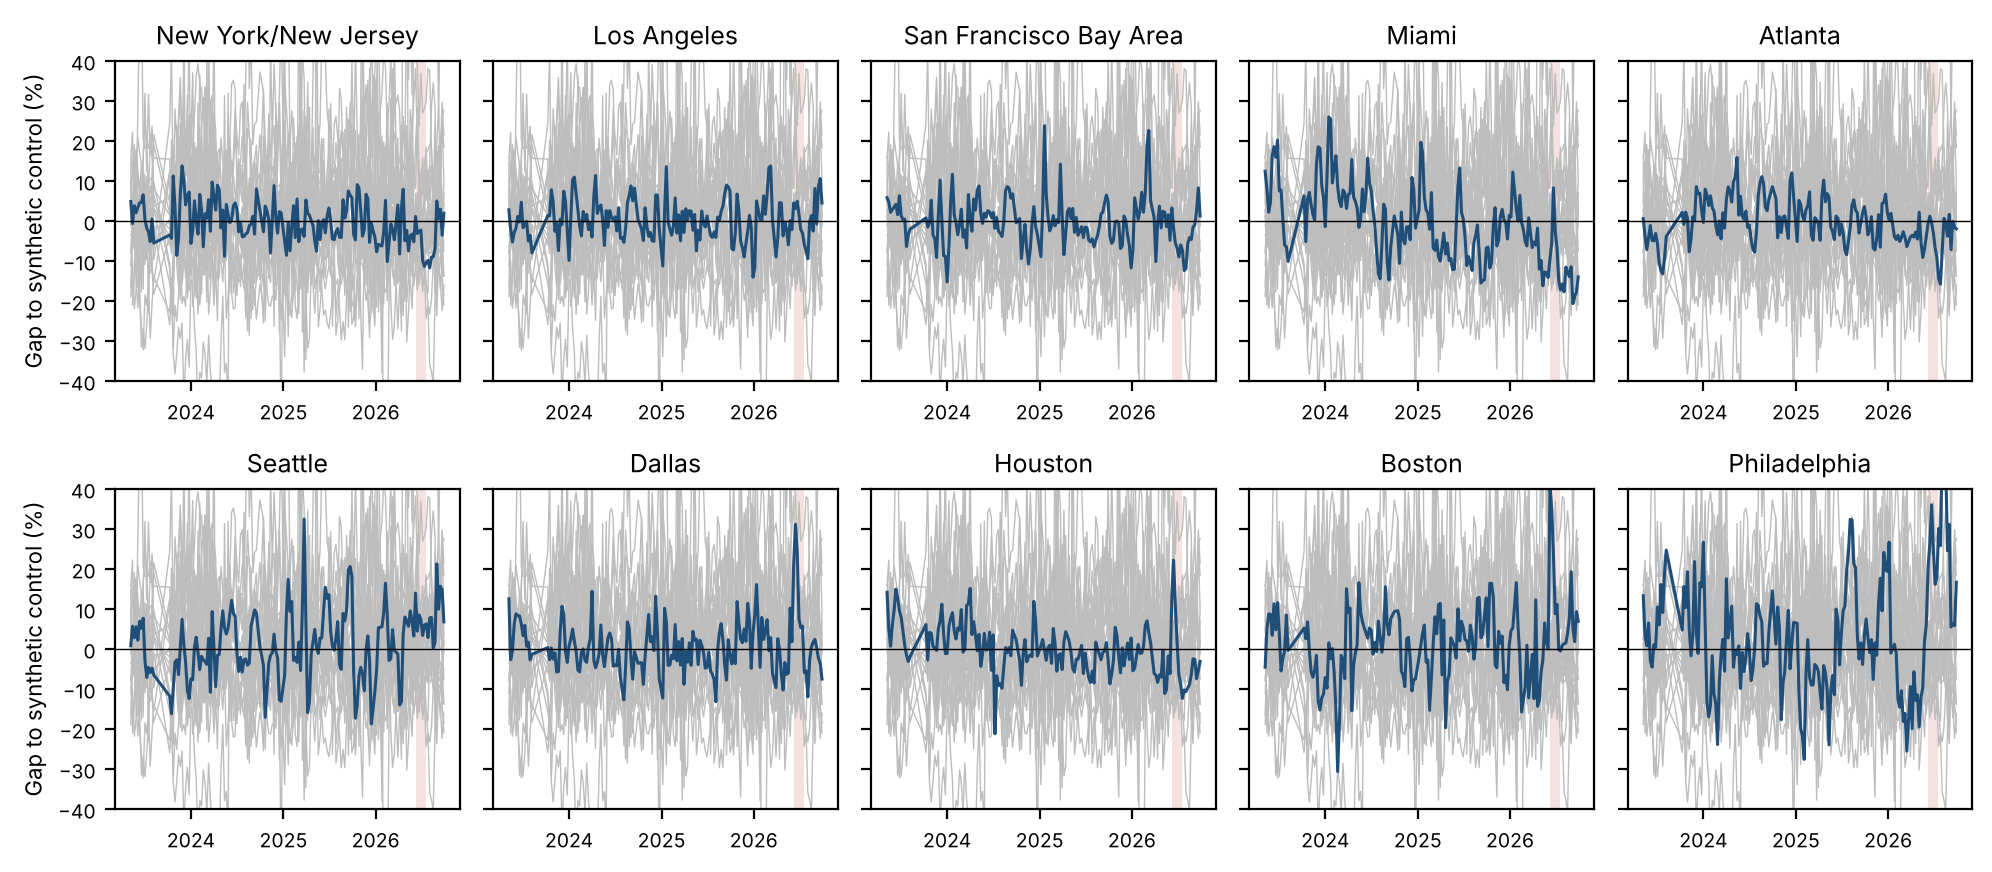

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4), sharey=True)
for ax, m in zip(axes.flat, HOSTS):
    for a in donors:
        g = gaps[a]; ax.plot(g.index, 100 * (np.exp(g) - 1), color='#bdbdbd', lw=0.5)
    g = gaps[m]; ax.plot(g.index, 100 * (np.exp(g) - 1), color='#1f4e79', lw=1.1)
    ax.axvspan(TW[0], TW[-1] + pd.Timedelta(days=6), color='#c0392b', alpha=0.15, lw=0)
    ax.axhline(0, color='k', lw=0.5); ax.set_ylim(-40, 40); ax.set_title(m); ax.tick_params(labelsize=7)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1])); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
for ax in axes[:, 0]: ax.set_ylabel('Gap to synthetic control (%)')
fig.tight_layout(); fig.savefig('output/supplement/figureS1_gaps.pdf'); fig.savefig('output/supplement/figureS1_gaps.png', dpi=200); plt.show()

### 7.2 Match-window effects with 95% confidence intervals

Table S3: $\beta_j$ of equation (1) in percent with heteroskedasticity-robust 95% intervals, for 2026 and for the same calendar days of 2025, and the difference between the two years in log points (×100) with its interval.

In [16]:
rows = []
for i, m in enumerate(HOSTS):
    r = {'area': m}
    for yr in (2026, 2025):
        fit_ = res[yr]['per_fit']; r[f'effect_{yr}'], r[f'lo_{yr}'], r[f'hi_{yr}'] = ci(fit_.params[f'w{i}'], fit_.bse[f'w{i}'])
    b = res[2026]['per_fit'].params[f'w{i}'] - res[2025]['per_fit'].params[f'w{i}']
    s = np.hypot(res[2026]['per_fit'].bse[f'w{i}'], res[2025]['per_fit'].bse[f'w{i}'])
    r['diff_x100'], r['diff_lo'], r['diff_hi'] = 100 * b, 100 * (b - 1.96 * s), 100 * (b + 1.96 * s)
    rows.append(r)
S3 = pd.DataFrame(rows).set_index('area')
for yr in (2026, 2025):
    fit_ = res[yr]['pooled_fit']; e, lo, hi = ci(fit_.params['window'], fit_.bse['window'])
    S3.loc[f'All hosts (pooled, clustered)', [f'effect_{yr}', f'lo_{yr}', f'hi_{yr}']] = [e, lo, hi]
S3.to_csv('output/supplement/tableS3_match_window.csv'); display(S3.round(1))

,effect_2026,lo_2026,hi_2026,effect_2025,lo_2025,hi_2025,diff_x100,diff_lo,diff_hi
area,,,,,,,,,
New York/New Jersey,4.3,0.1,8.7,3.8,-0.6,8.3,0.5,-5.4,6.5
Los Angeles,2.8,-1.1,6.9,2.1,-1.6,6.0,0.7,-4.7,6.1
San Francisco Bay Area,0.2,-4.5,5.2,1.8,-3.0,6.8,-1.5,-8.3,5.3
Miami,13.9,7.2,20.9,9.6,4.4,15.1,3.8,-3.9,11.6
Atlanta,1.1,-3.2,5.7,-1.4,-5.9,3.2,2.6,-3.8,8.9
Seattle,0.3,-5.7,6.6,12.3,6.6,18.2,-11.3,-19.4,-3.3
Dallas,16.2,9.8,23.1,-0.2,-4.9,4.7,15.3,7.8,22.7
Houston,20.8,13.5,28.5,2.8,-1.7,7.6,16.1,8.4,23.7
Boston,21.7,13.3,30.6,5.3,0.1,10.9,14.4,5.6,23.2


### 7.3 Pooled weekly effects with 95% intervals, during and after the tournament

In [17]:
rows = [('Six tournament weeks',) + ci(fw.params['host:tourn'], fw.bse['host:tourn']),
        ('Eight weeks after the final',) + ci(fw.params['host:post'], fw.bse['host:post'])]
for k, w in enumerate(TW, 1):
    rows.append((f'Week starting {w.date()}',) + ci(fw2.params[f'h{k}'], fw2.bse[f'h{k}']))
S4 = pd.DataFrame(rows, columns=['period', 'effect_pct', 'lo95', 'hi95']).set_index('period')
S4.to_csv('output/supplement/tableS4_weekly.csv'); display(S4.round(1))

,effect_pct,lo95,hi95
period,,,
Six tournament weeks,-4.6,-14.8,6.8
Eight weeks after the final,-7.3,-18.4,5.2
Week starting 2026-06-08,1.3,-12.2,16.9
Week starting 2026-06-15,1.3,-10.4,14.5
Week starting 2026-06-22,-0.4,-10.7,11.1
Week starting 2026-06-29,-6.6,-16.7,4.7
Week starting 2026-07-06,-10.3,-20.6,1.3
Week starting 2026-07-13,-12.0,-21.6,-1.2


### 7.4 Overlapping match windows

When two matches in the same host area are less than four days apart their windows overlap. The window indicator is then simply one on the shared days, and the timing profile assigns each day to the nearest match.

In [18]:
rows = []
for m in HOSTS:
    ds = pd.Series(sorted(match_dates[m]))
    rows.append({'area': m, 'matches': len(ds), 'window_days_if_disjoint': 4 * len(ds), 'distinct_window_days': len(window_days[m]),
                 'min_days_between_matches': int(ds.diff().dt.days.min())})
S5 = pd.DataFrame(rows).set_index('area'); S5.to_csv('output/supplement/tableS5_windows.csv'); display(S5)
print('Areas with overlapping windows:', list(S5.index[S5.distinct_window_days < S5.window_days_if_disjoint]))

,matches,window_days_if_disjoint,distinct_window_days,min_days_between_matches
area,,,,
New York/New Jersey,8,32,27,2
Los Angeles,8,32,28,3
San Francisco Bay Area,6,24,20,3
Miami,7,28,26,3
Atlanta,8,32,28,3
Seattle,6,24,22,2
Dallas,9,36,29,2
Houston,7,28,23,3
Boston,7,28,24,3


Areas with overlapping windows: ['New York/New Jersey', 'Los Angeles', 'San Francisco Bay Area', 'Miami', 'Atlanta', 'Seattle', 'Dallas', 'Houston', 'Boston', 'Philadelphia']


### 7.5 Connecting traffic through comparison airports

CBP counts passengers at the airport where they first enter the United States, so a supporter connecting through a comparison airport is counted there. Four checks.

(a) Synthetic control rebuilt without the eight main connecting hubs (O'Hare, Dulles, Denver, Detroit, Minneapolis, Charlotte, Phoenix, Salt Lake City).
(b) Daily match-window regression with these hubs removed, so that the day effects are estimated without them.
(c) Weekly arrivals at the hubs against the other comparison airports during the tournament weeks, with the same weeks of 2025 as a placebo.
(d) Daily arrivals at the hubs against the other comparison airports in the match windows of Kansas City, which has no passport control, so its international visitors must enter elsewhere.

In [19]:
# (a) synthetic control without hubs
pool = [a for a in donors if a not in HUBS]
plac_nh = [run_sc(a, [b for b in pool if b != a])['ratio'] for a in pool]
rows = []
for m in HOSTS:
    r_ = run_sc(m, pool)
    rows.append({'area': m, 'uplift_main': sctab.loc[m, 'uplift_pct'], 'uplift_no_hubs': r_['uplift'],
                 'excess_no_hubs_thousands': r_['excess'] / 1000,
                 'rank_no_hubs': f"{int(np.sum(np.array(plac_nh) >= r_['ratio'])) + 1} of {len(pool) + 1}"})
S6a = pd.DataFrame(rows).set_index('area')
print('Comparison airports without hubs:', pool)
print('Excess without hubs (thousands): major %.0f, secondary %.0f, all %.0f' % (
    S6a.loc[MAJOR].excess_no_hubs_thousands.sum(), S6a.loc[SECONDARY].excess_no_hubs_thousands.sum(), S6a.excess_no_hubs_thousands.sum()))

# (b) daily regression without hubs
for yr in (2026, 2025):
    d = design(yr); d = d[~d.area.isin(HUBS)]
    per_ = smf.ols('ly ~ C(area) + C(date) + ' + ' + '.join(f'w{i}' for i in range(len(HOSTS))), data=d).fit(cov_type='HC1')
    S6a[f'window_no_hubs_{yr}'] = [100 * (np.exp(per_.params[f'w{i}']) - 1) for i in range(len(HOSTS))]
S6a['window_main_2026'] = mw['effect_pct_2026']; S6a['window_main_2025'] = mw['effect_pct_2025']
S6a.to_csv('output/supplement/tableS6_no_hubs.csv'); display(S6a.round(1))

Comparison airports without hubs: ['BWI', 'RDU', 'STL', 'LAS', 'SAN', 'PDX', 'HNL', 'MCO', 'TPA', 'AUS', 'SAT']
Excess without hubs (thousands): major -277, secondary 18, all -259


,uplift_main,uplift_no_hubs,excess_no_hubs_thousands,rank_no_hubs,window_no_hubs_2026,window_no_hubs_2025,window_main_2026,window_main_2025
area,,,,,,,,
New York/New Jersey,-4.8,-11.7,-152.0,1 of 12,1.0,1.9,4.3,3.8
Los Angeles,1.4,-2.4,-15.6,10 of 12,-0.6,-0.0,2.8,2.1
San Francisco Bay Area,-4.4,-11.3,-48.3,3 of 12,-3.3,0.3,0.2,1.8
Miami,-5.5,-7.3,-61.1,7 of 12,11.0,7.3,13.9,9.6
Atlanta,-3.2,-7.8,-18.3,5 of 12,-1.6,-2.3,1.1,-1.4
Seattle,7.2,-0.3,-0.5,12 of 12,-2.9,11.0,0.3,12.3
Dallas,15.4,10.2,23.9,3 of 12,12.9,-1.3,16.2,-0.2
Houston,4.8,0.2,0.4,4 of 12,16.6,0.9,20.8,2.8
Boston,18.9,4.6,8.9,7 of 12,17.8,3.8,21.7,5.3


In [20]:
# (c) hubs versus other comparison airports, weekly
cw = W[COMPARISON].loc[:TW[-1] + pd.Timedelta(weeks=8)].stack().rename('ly').reset_index(); cw.columns = ['week', 'area', 'ly']; cw = cw.dropna()
cw['hub'] = cw.area.isin(HUBS).astype(int)
TW25 = TW - pd.Timedelta(weeks=52)
cw['t26'] = (cw.week.isin(TW) & (cw.hub == 1)).astype(int); cw['t25'] = (cw.week.isin(TW25) & (cw.hub == 1)).astype(int)
fc = smf.ols('ly ~ C(area) + C(week) + t26 + t25', data=cw).fit(cov_type='cluster', cov_kwds={'groups': cw.area})
hub_week = {'2026 tournament weeks': ci(fc.params['t26'], fc.bse['t26']), 'Same weeks of 2025': ci(fc.params['t25'], fc.bse['t25'])}

# (d) hubs in the match windows of Kansas City, daily
kc_dates = sorted(matches.loc[matches.metro == 'Kansas City', 'date'])
kc_win = {x for d_ in kc_dates for x in pd.date_range(d_ - pd.Timedelta(days=2), d_ + pd.Timedelta(days=1))}
hub_kc = {}
for yr in (2026, 2025):
    shift = pd.Timedelta(days=364 * (2026 - yr))
    d = daily[daily.area.isin(COMPARISON) & (daily.date >= f'{yr}-05-01') & (daily.date <= f'{yr}-08-31') & (daily.nonusa > 0)].copy()
    d['ly'] = np.log(d.nonusa)
    d['kc'] = [int(a in HUBS and (t + shift) in kc_win) for a, t in zip(d.area, d.date)]
    fk = smf.ols('ly ~ C(area) + C(date) + kc', data=d).fit(cov_type='cluster', cov_kwds={'groups': d.area})
    hub_kc[f'Kansas City windows, {yr}'] = ci(fk.params['kc'], fk.bse['kc'])
S6b = pd.DataFrame({**hub_week, **hub_kc}, index=['effect_pct', 'lo95', 'hi95']).T
print('Kansas City matches:', [d_.date() for d_ in kc_dates])
S6b.to_csv('output/supplement/tableS6b_hub_checks.csv'); display(S6b.round(1))

Kansas City matches: [datetime.date(2026, 6, 16), datetime.date(2026, 6, 20), datetime.date(2026, 6, 25), datetime.date(2026, 6, 27), datetime.date(2026, 7, 3), datetime.date(2026, 7, 11)]


,effect_pct,lo95,hi95
2026 tournament weeks,-10.9,-22.0,1.8
Same weeks of 2025,-3.1,-14.3,9.5
"Kansas City windows, 2026",-8.2,-13.4,-2.6
"Kansas City windows, 2025",-8.7,-17.9,1.5


### 7.6 Summary of the checks

In [21]:
print('Synthetic control fit before the tournament (RMSPE, %%): hosts %.1f to %.1f' % (S2.pre_rmspe_pct.min(), S2.pre_rmspe_pct.max()))
for m in HOSTS:
    print('  %-24s uplift %5.1f%%  90%% interval %6.1f to %5.1f  after final %5.1f%%  | window 2026 %5.1f [%5.1f, %5.1f]  no hubs: SC %5.1f, window %5.1f' % (
        m, S2.loc[m, 'uplift_pct'], S2.loc[m, 'uplift_lo90'], S2.loc[m, 'uplift_hi90'], S2.loc[m, 'after_final_pct'],
        S3.loc[m, 'effect_2026'], S3.loc[m, 'lo_2026'], S3.loc[m, 'hi_2026'], S6a.loc[m, 'uplift_no_hubs'], S6a.loc[m, 'window_no_hubs_2026']))
print(S4.round(1).to_string()); print(S6b.round(1).to_string())

Synthetic control fit before the tournament (RMSPE, %): hosts 4.8 to 12.1
  New York/New Jersey      uplift  -4.8%  90% interval  -12.7 to  -0.0  after final  -4.7%  | window 2026   4.3 [  0.1,   8.7]  no hubs: SC -11.7, window   1.0
  Los Angeles              uplift   1.4%  90% interval   -7.4 to   6.8  after final   0.4%  | window 2026   2.8 [ -1.1,   6.9]  no hubs: SC  -2.4, window  -0.6
  San Francisco Bay Area   uplift  -4.4%  90% interval  -13.6 to   1.3  after final  -3.5%  | window 2026   0.2 [ -4.5,   5.2]  no hubs: SC -11.3, window  -3.3
  Miami                    uplift  -5.5%  90% interval  -19.5 to   3.6  after final -15.6%  | window 2026  13.9 [  7.2,  20.9]  no hubs: SC  -7.3, window  11.0
  Atlanta                  uplift  -3.2%  90% interval  -12.0 to   2.2  after final  -4.8%  | window 2026   1.1 [ -3.2,   5.7]  no hubs: SC  -7.8, window  -1.6
  Seattle                  uplift   7.2%  90% interval   -7.8 to  16.7  after final   8.5%  | window 2026   0.3 [ -5.7,   6.6]